<a href="https://colab.research.google.com/github/aadeshbhamare/DataScience-Week2---WeIntern-Project/blob/main/notebooks/Task_03_Sales_Prediction.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
# SECTION 1 - IMPORT LIBRARIES

import os
import warnings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, RandomizedSearchCV
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    r2_score
)

import joblib

warnings.filterwarnings("ignore")

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", "{:.2f}".format)

sns.set_theme(style="whitegrid")

print("All libraries imported successfully!")

All libraries imported successfully!


In [ ]:
# SECTION 2 - LOAD CLEANED DATASETS

BASE_URL = "https://raw.githubusercontent.com/aadeshbhamare/DataScience-Week2---WeIntern-Project/main/"

# Load cleaned datasets
train_clean = pd.read_csv(
    BASE_URL + "data/cleaned/cleaned_train.csv",
    parse_dates=["date"]
)

test_clean = pd.read_csv(
    BASE_URL + "data/cleaned/cleaned_test.csv",
    parse_dates=["date"]
)

store_clean = pd.read_csv(
    BASE_URL + "data/cleaned/cleaned_store.csv"
)

# Load original sample submission
sample_submission = pd.read_csv(
    BASE_URL + "data/raw/sample_submission.csv"
)

print("All datasets loaded successfully!")

print("\nTRAIN DATASET")
print("Shape:", train_clean.shape)

print("\nTEST DATASET")
print("Shape:", test_clean.shape)

print("\nSTORE DATASET")
print("Shape:", store_clean.shape)

print("\nSAMPLE SUBMISSION")
print("Shape:", sample_submission.shape)

All datasets loaded successfully!

TRAIN DATASET
Shape: (1017209, 9)

TEST DATASET
Shape: (41088, 8)

STORE DATASET
Shape: (1115, 13)

SAMPLE SUBMISSION
Shape: (41088, 2)


In [ ]:
# SECTION 2.1 - BASIC DATASET VERIFICATION

print("=" * 60)
print("DATASET VERIFICATION")
print("=" * 60)

datasets = {
    "Train": train_clean,
    "Test": test_clean,
    "Store": store_clean,
    "Sample Submission": sample_submission
}

for name, df in datasets.items():

    print(f"\n{name} Dataset")
    print("-" * 40)

    print("Shape:", df.shape)
    print("Duplicate Rows:", df.duplicated().sum())
    print("Missing Values:", df.isnull().sum().sum())

    print("\nColumns:")
    print(df.columns.tolist())

DATASET VERIFICATION

Train Dataset
----------------------------------------
Shape: (1017209, 9)
Duplicate Rows: 0
Missing Values: 0

Columns:
['store', 'dayofweek', 'date', 'sales', 'customers', 'open', 'promo', 'stateholiday', 'schoolholiday']

Test Dataset
----------------------------------------
Shape: (41088, 8)
Duplicate Rows: 0
Missing Values: 0

Columns:
['id', 'store', 'dayofweek', 'date', 'open', 'promo', 'stateholiday', 'schoolholiday']

Store Dataset
----------------------------------------
Shape: (1115, 13)
Duplicate Rows: 0
Missing Values: 0

Columns:
['store', 'storetype', 'assortment', 'competitiondistance', 'competitionopensincemonth', 'competitionopensinceyear', 'promo2', 'promo2sinceweek', 'promo2sinceyear', 'promointerval', 'competitiondistance_missing', 'promo2_not_applicable', 'competition_opening_info_missing']

Sample Submission Dataset
----------------------------------------
Shape: (41088, 2)
Duplicate Rows: 0
Missing Values: 0

Columns:
['Id', 'Sales']


In [ ]:
# SECTION 3 - MERGE TRAIN AND STORE DATASETS

train_df = pd.merge(
    train_clean,
    store_clean,
    on="store",
    how="left",
    validate="many_to_one"
)

print("Train and Store datasets merged successfully!")

print("\nMerged Train Dataset Shape:", train_df.shape)

print("\nFirst 5 Rows:")
display(train_df.head())

print("\nMissing Values After Merge:")
print(train_df.isnull().sum().sum())

Train and Store datasets merged successfully!

Merged Train Dataset Shape: (1017209, 21)

First 5 Rows:


,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval,competitiondistance_missing,promo2_not_applicable,competition_opening_info_missing
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9,2008,0,0,0,No Promo2,0,1,0
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11,2007,1,13,2010,"Jan,Apr,Jul,Oct",0,0,0
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12,2006,1,14,2011,"Jan,Apr,Jul,Oct",0,0,0
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9,2009,0,0,0,No Promo2,0,1,0
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4,2015,0,0,0,No Promo2,0,1,0



Missing Values After Merge:
0


In [ ]:
# MERGE TEST AND STORE DATASETS

test_df = pd.merge(
    test_clean,
    store_clean,
    on="store",
    how="left",
    validate="many_to_one"
)

print("Test and Store datasets merged successfully!")

print("\nMerged Test Dataset Shape:", test_df.shape)

print("\nFirst 5 Rows:")
display(test_df.head())

print("\nMissing Values After Merge:")
print(test_df.isnull().sum().sum())

Test and Store datasets merged successfully!

Merged Test Dataset Shape: (41088, 20)

First 5 Rows:


,id,store,dayofweek,date,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval,competitiondistance_missing,promo2_not_applicable,competition_opening_info_missing
0,1,1,4,2015-09-17,1,1,0,0,c,a,1270.00,9,2008,0,0,0,No Promo2,0,1,0
1,2,3,4,2015-09-17,1,1,0,0,a,a,14130.00,12,2006,1,14,2011,"Jan,Apr,Jul,Oct",0,0,0
2,3,7,4,2015-09-17,1,1,0,0,a,c,24000.00,4,2013,0,0,0,No Promo2,0,1,0
3,4,8,4,2015-09-17,1,1,0,0,a,a,7520.00,10,2014,0,0,0,No Promo2,0,1,0
4,5,9,4,2015-09-17,1,1,0,0,a,c,2030.00,8,2000,0,0,0,No Promo2,0,1,0



Missing Values After Merge:
0


In [ ]:
# SECTION 3.1 - MERGE VALIDATION

print("=" * 60)
print("MERGE VALIDATION")
print("=" * 60)

print("\nTRAIN DATA")
print("Original Train Rows:", len(train_clean))
print("Merged Train Rows:", len(train_df))
print("Row Count Match:", len(train_clean) == len(train_df))

print("\nTEST DATA")
print("Original Test Rows:", len(test_clean))
print("Merged Test Rows:", len(test_df))
print("Row Count Match:", len(test_clean) == len(test_df))

print("\nSTORE VALIDATION")
print("Unique Stores in Store Dataset:", store_clean["store"].nunique())
print("Unique Stores in Train:", train_df["store"].nunique())
print("Unique Stores in Test:", test_df["store"].nunique())

print("\nFinal Shapes:")
print("Train:", train_df.shape)
print("Test:", test_df.shape)

MERGE VALIDATION

TRAIN DATA
Original Train Rows: 1017209
Merged Train Rows: 1017209
Row Count Match: True

TEST DATA
Original Test Rows: 41088
Merged Test Rows: 41088
Row Count Match: True

STORE VALIDATION
Unique Stores in Store Dataset: 1115
Unique Stores in Train: 1115
Unique Stores in Test: 856

Final Shapes:
Train: (1017209, 21)
Test: (41088, 20)


In [ ]:
# SECTION 4.1 - DATE FEATURE ENGINEERING

def create_date_features(df):

    df = df.copy()

    df["year"] = df["date"].dt.year
    df["month"] = df["date"].dt.month
    df["day"] = df["date"].dt.day

    df["dayofyear"] = df["date"].dt.dayofyear
    df["weekofyear"] = df["date"].dt.isocalendar().week.astype(int)

    df["is_weekend"] = (df["dayofweek"] >= 6).astype(int)

    df["is_month_start"] = df["date"].dt.is_month_start.astype(int)
    df["is_month_end"] = df["date"].dt.is_month_end.astype(int)

    return df


train_df = create_date_features(train_df)
test_df = create_date_features(test_df)

print("Date features created successfully!")

display(train_df.head())

Date features created successfully!


,store,dayofweek,date,sales,customers,open,promo,stateholiday,schoolholiday,storetype,assortment,competitiondistance,competitionopensincemonth,competitionopensinceyear,promo2,promo2sinceweek,promo2sinceyear,promointerval,competitiondistance_missing,promo2_not_applicable,competition_opening_info_missing,year,month,day,dayofyear,weekofyear,is_weekend,is_month_start,is_month_end
0,1,5,2015-07-31,5263,555,1,1,0,1,c,a,1270.00,9,2008,0,0,0,No Promo2,0,1,0,2015,7,31,212,31,0,0,1
1,2,5,2015-07-31,6064,625,1,1,0,1,a,a,570.00,11,2007,1,13,2010,"Jan,Apr,Jul,Oct",0,0,0,2015,7,31,212,31,0,0,1
2,3,5,2015-07-31,8314,821,1,1,0,1,a,a,14130.00,12,2006,1,14,2011,"Jan,Apr,Jul,Oct",0,0,0,2015,7,31,212,31,0,0,1
3,4,5,2015-07-31,13995,1498,1,1,0,1,c,c,620.00,9,2009,0,0,0,No Promo2,0,1,0,2015,7,31,212,31,0,0,1
4,5,5,2015-07-31,4822,559,1,1,0,1,a,a,29910.00,4,2015,0,0,0,No Promo2,0,1,0,2015,7,31,212,31,0,0,1


In [ ]:
# SECTION 4.2 - COMPETITION FEATURE ENGINEERING

def create_competition_features(df):

    df = df.copy()

    known_competition = (
        (df["competitionopensincemonth"] > 0) &
        (df["competitionopensinceyear"] > 0)
    )

    df["competition_age_months"] = np.where(
        known_competition,
        (df["year"] - df["competitionopensinceyear"]) * 12
        + (df["month"] - df["competitionopensincemonth"]),
        0
    )

    df["competition_age_months"] = (
        df["competition_age_months"].clip(lower=0)
    )

    return df


train_df = create_competition_features(train_df)
test_df = create_competition_features(test_df)

print("Competition features created successfully!")

display(
    train_df[
        ["store", "date", "competitionopensincemonth",
         "competitionopensinceyear", "competition_age_months"]
    ].head(10)
)

Competition features created successfully!


,store,date,competitionopensincemonth,competitionopensinceyear,competition_age_months
0,1,2015-07-31,9,2008,82
1,2,2015-07-31,11,2007,92
2,3,2015-07-31,12,2006,103
3,4,2015-07-31,9,2009,70
4,5,2015-07-31,4,2015,3
5,6,2015-07-31,12,2013,19
6,7,2015-07-31,4,2013,27
7,8,2015-07-31,10,2014,9
8,9,2015-07-31,8,2000,179
9,10,2015-07-31,9,2009,70


In [ ]:
# SECTION 4.3 - PROMO2 FEATURE ENGINEERING

def create_promo2_features(df):

    df = df.copy()

    def check_promo2_active(row):

        if row["promo2"] != 1:
            return 0

        interval = str(row["promointerval"])

        if interval == "No Promo2":
            return 0

        active_months = [
            month.strip()
            for month in interval.split(",")
        ]

        current_month = row["date"].strftime("%b")

        # Check whether Promo2 has started
        current_week = int(row["date"].isocalendar().week)

        current_year = row["date"].year

        current_period = current_year * 100 + current_week

        start_period = (
            int(row["promo2sinceyear"]) * 100
            + int(row["promo2sinceweek"])
        )

        if current_period < start_period:
            return 0

        return int(current_month in active_months)

    df["promo2_active"] = df.apply(
        check_promo2_active,
        axis=1
    )

    return df


train_df = create_promo2_features(train_df)
test_df = create_promo2_features(test_df)

print("Promo2 features created successfully!")

print("\nPromo2 Active Distribution:")
display(train_df["promo2_active"].value_counts())

Promo2 features created successfully!

Promo2 Active Distribution:


,count
promo2_active,
0,870372
1,146837


In [ ]:
# SECTION 4.4 - FEATURE ENGINEERING VALIDATION

new_features = [
    "year",
    "month",
    "day",
    "dayofyear",
    "weekofyear",
    "is_weekend",
    "is_month_start",
    "is_month_end",
    "competition_age_months",
    "promo2_active"
]

print("=" * 60)
print("FEATURE ENGINEERING VALIDATION")
print("=" * 60)

print("\nNew Features:")
print(new_features)

print("\nTrain Dataset Shape:", train_df.shape)
print("Test Dataset Shape:", test_df.shape)

print("\nMissing Values in New Train Features:")
print(train_df[new_features].isnull().sum())

print("\nMissing Values in New Test Features:")
print(test_df[new_features].isnull().sum())

print("\nTrain Feature Sample:")
display(train_df[new_features].head())

print("\nTest Feature Sample:")
display(test_df[new_features].head())

FEATURE ENGINEERING VALIDATION

New Features:
['year', 'month', 'day', 'dayofyear', 'weekofyear', 'is_weekend', 'is_month_start', 'is_month_end', 'competition_age_months', 'promo2_active']

Train Dataset Shape: (1017209, 31)
Test Dataset Shape: (41088, 30)

Missing Values in New Train Features:
year                      0
month                     0
day                       0
dayofyear                 0
weekofyear                0
is_weekend                0
is_month_start            0
is_month_end              0
competition_age_months    0
promo2_active             0
dtype: int64

Missing Values in New Test Features:
year                      0
month                     0
day                       0
dayofyear                 0
weekofyear                0
is_weekend                0
is_month_start            0
is_month_end              0
competition_age_months    0
promo2_active             0
dtype: int64

Train Feature Sample:


,year,month,day,dayofyear,weekofyear,is_weekend,is_month_start,is_month_end,competition_age_months,promo2_active
0,2015,7,31,212,31,0,0,1,82,0
1,2015,7,31,212,31,0,0,1,92,1
2,2015,7,31,212,31,0,0,1,103,1
3,2015,7,31,212,31,0,0,1,70,0
4,2015,7,31,212,31,0,0,1,3,0



Test Feature Sample:


,year,month,day,dayofyear,weekofyear,is_weekend,is_month_start,is_month_end,competition_age_months,promo2_active
0,2015,9,17,260,38,0,0,0,84,0
1,2015,9,17,260,38,0,0,0,105,0
2,2015,9,17,260,38,0,0,0,29,0
3,2015,9,17,260,38,0,0,0,11,0
4,2015,9,17,260,38,0,0,0,181,0


In [ ]:
# SECTION 5.1 - FEATURE SELECTION

target_column = "sales"

feature_columns = [
    # Store Information
    "store",
    "storetype",
    "assortment",

    # Competition Information
    "competitiondistance",
    "competitiondistance_missing",
    "competitionopensincemonth",
    "competitionopensinceyear",
    "competition_opening_info_missing",
    "competition_age_months",

    # Promotion Information
    "promo",
    "promo2",
    "promo2sinceweek",
    "promo2sinceyear",
    "promointerval",
    "promo2_not_applicable",
    "promo2_active",

    # Holiday Information
    "stateholiday",
    "schoolholiday",

    # Date Information
    "dayofweek",
    "year",
    "month",
    "day",
    "dayofyear",
    "weekofyear",
    "is_weekend",
    "is_month_start",
    "is_month_end"
]

print("Total Selected Features:", len(feature_columns))

print("\nSelected Features:")
for feature in feature_columns:
    print(feature)

Total Selected Features: 27

Selected Features:
store
storetype
assortment
competitiondistance
competitiondistance_missing
competitionopensincemonth
competitionopensinceyear
competition_opening_info_missing
competition_age_months
promo
promo2
promo2sinceweek
promo2sinceyear
promointerval
promo2_not_applicable
promo2_active
stateholiday
schoolholiday
dayofweek
year
month
day
dayofyear
weekofyear
is_weekend
is_month_start
is_month_end


In [ ]:
# SECTION 5.2 - PREPARE MODEL DATA

# Keep only open stores for model training
model_train_df = train_df[train_df["open"] == 1].copy()

# Prepare test data
model_test_df = test_df.copy()

# Separate features and target
X = model_train_df[feature_columns].copy()
y = model_train_df[target_column].copy()

X_test = model_test_df[feature_columns].copy()

print("Training Data Shape:", X.shape)
print("Target Shape:", y.shape)
print("Test Data Shape:", X_test.shape)

print("\nTraining Date Range:")
print(model_train_df["date"].min(), "to", model_train_df["date"].max())

print("\nOpen Store Training Records:", len(model_train_df))
print("Closed Store Training Records:", len(train_df) - len(model_train_df))

print("\nClosed Stores in Test:", (model_test_df["open"] == 0).sum())
print("Open Stores in Test:", (model_test_df["open"] == 1).sum())

Training Data Shape: (844392, 27)
Target Shape: (844392,)
Test Data Shape: (41088, 27)

Training Date Range:
2013-01-01 00:00:00 to 2015-07-31 00:00:00

Open Store Training Records: 844392
Closed Store Training Records: 172817

Closed Stores in Test: 5984
Open Stores in Test: 35104


In [ ]:
# SECTION 5.3 - FEATURE VALIDATION

print("=" * 60)
print("FEATURE VALIDATION")
print("=" * 60)

print("\nMissing Values in X:")
print(X.isnull().sum().sum())

print("\nMissing Values in X_test:")
print(X_test.isnull().sum().sum())

print("\nFeatures Present in Both Datasets:")
print(list(X.columns) == list(X_test.columns))

print("\nTarget Column:", target_column)

print("\nCustomers Included:", "customers" in X.columns)
print("ID Included:", "id" in X.columns)
print("Date Included:", "date" in X.columns)

FEATURE VALIDATION

Missing Values in X:
0

Missing Values in X_test:
0

Features Present in Both Datasets:
True

Target Column: sales

Customers Included: False
ID Included: False
Date Included: False


In [ ]:
# SECTION 6.1 - CHRONOLOGICAL TRAIN-VALIDATION SPLIT

# Sort data by date
model_train_df = model_train_df.sort_values("date").reset_index(drop=True)

# Get unique dates
unique_dates = np.sort(model_train_df["date"].unique())

# Find 80% date cutoff
split_index = int(len(unique_dates) * 0.8)
cutoff_date = unique_dates[split_index]

# Split training and validation data
train_mask = model_train_df["date"] < cutoff_date
valid_mask = model_train_df["date"] >= cutoff_date

X_train = model_train_df.loc[train_mask, feature_columns].copy()
X_valid = model_train_df.loc[valid_mask, feature_columns].copy()

y_train = model_train_df.loc[train_mask, target_column].copy()
y_valid = model_train_df.loc[valid_mask, target_column].copy()

print("=" * 60)
print("CHRONOLOGICAL TRAIN-VALIDATION SPLIT")
print("=" * 60)

print("\nCutoff Date:", cutoff_date)

print("\nTraining Data Shape:", X_train.shape)
print("Validation Data Shape:", X_valid.shape)

print("\nTraining Date Range:")
print(
    model_train_df.loc[train_mask, "date"].min(),
    "to",
    model_train_df.loc[train_mask, "date"].max()
)

print("\nValidation Date Range:")
print(
    model_train_df.loc[valid_mask, "date"].min(),
    "to",
    model_train_df.loc[valid_mask, "date"].max()
)

print("\nTraining Percentage:",
      round(len(X_train) / len(model_train_df) * 100, 2), "%")

print("Validation Percentage:",
      round(len(X_valid) / len(model_train_df) * 100, 2), "%")

CHRONOLOGICAL TRAIN-VALIDATION SPLIT

Cutoff Date: 2015-01-24T00:00:00.000000000

Training Data Shape: (669308, 27)
Validation Data Shape: (175084, 27)

Training Date Range:
2013-01-01 00:00:00 to 2015-01-23 00:00:00

Validation Date Range:
2015-01-24 00:00:00 to 2015-07-31 00:00:00

Training Percentage: 79.27 %
Validation Percentage: 20.73 %


In [ ]:
# SECTION 6.2 - SPLIT VALIDATION

print("=" * 60)
print("SPLIT VALIDATION")
print("=" * 60)

print("\nTraining and Validation Rows:")
print(len(X_train), "+", len(X_valid), "=", len(model_train_df))

print("\nDate Overlap:",
      model_train_df.loc[train_mask, "date"].max() >=
      model_train_df.loc[valid_mask, "date"].min())

print("\nMissing Values in X_train:", X_train.isnull().sum().sum())
print("Missing Values in X_valid:", X_valid.isnull().sum().sum())

print("\nMissing Values in y_train:", y_train.isnull().sum())
print("Missing Values in y_valid:", y_valid.isnull().sum())

SPLIT VALIDATION

Training and Validation Rows:
669308 + 175084 = 844392

Date Overlap: False

Missing Values in X_train: 0
Missing Values in X_valid: 0

Missing Values in y_train: 0
Missing Values in y_valid: 0


In [ ]:
# SECTION 7.1 - FEATURE DATA TYPE VALIDATION

print("=" * 60)
print("FEATURE DATA TYPE VALIDATION")
print("=" * 60)

print("\nFeature Data Types:")
print(X_train.dtypes)

print("\nObject Columns:")
object_columns = X_train.select_dtypes(include=["object"]).columns.tolist()
print(object_columns)

print("\nEmpty Strings in Object Columns:")
for column in object_columns:
    count = (
        X_train[column]
        .astype(str)
        .str.strip()
        .eq("")
        .sum()
    )
    print(column, ":", count)

print("\nNumerical Columns:")
numeric_columns = X_train.select_dtypes(include=np.number).columns.tolist()
print(numeric_columns)

print("\nTotal Features:", X_train.shape[1])

FEATURE DATA TYPE VALIDATION

Feature Data Types:
store                                 int64
storetype                            object
assortment                           object
competitiondistance                 float64
competitiondistance_missing           int64
competitionopensincemonth             int64
competitionopensinceyear              int64
competition_opening_info_missing      int64
competition_age_months                int64
promo                                 int64
promo2                                int64
promo2sinceweek                       int64
promo2sinceyear                       int64
promointerval                        object
promo2_not_applicable                 int64
promo2_active                         int64
stateholiday                         object
schoolholiday                         int64
dayofweek                             int64
year                                  int32
month                                 int32
day                       

In [ ]:
# SECTION 7.2 - CREATE PREPROCESSING PIPELINE

categorical_features = [
    "storetype",
    "assortment",
    "promointerval",
    "stateholiday"
]

numerical_features = [
    column for column in feature_columns
    if column not in categorical_features
]

# One-Hot Encoding
preprocessor = ColumnTransformer(
    transformers=[
        (
            "categorical",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        ),
        (
            "numerical",
            "passthrough",
            numerical_features
        )
    ]
)

print("Categorical Features:", categorical_features)
print("\nNumerical Features:", len(numerical_features))
print("Total Original Features:", len(feature_columns))
print("\nPreprocessing Pipeline Created Successfully!")

Categorical Features: ['storetype', 'assortment', 'promointerval', 'stateholiday']

Numerical Features: 23
Total Original Features: 27

Preprocessing Pipeline Created Successfully!


In [ ]:
# SECTION 7.3 - LINEAR REGRESSION MODEL

linear_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        ("model", LinearRegression())
    ]
)

print("Linear Regression Pipeline Created Successfully!")

Linear Regression Pipeline Created Successfully!


In [ ]:
# SECTION 7.4.1 - CHECK MIXED DATA TYPES

for column in categorical_features:

    print("\nColumn:", column)

    print("Training Data Types:")
    print(X_train[column].apply(type).value_counts())

    print("Validation Data Types:")
    print(X_valid[column].apply(type).value_counts())


Column: storetype
Training Data Types:
storetype
<class 'str'>    669308
Name: count, dtype: int64
Validation Data Types:
storetype
<class 'str'>    175084
Name: count, dtype: int64

Column: assortment
Training Data Types:
assortment
<class 'str'>    669308
Name: count, dtype: int64
Validation Data Types:
assortment
<class 'str'>    175084
Name: count, dtype: int64

Column: promointerval
Training Data Types:
promointerval
<class 'str'>    669308
Name: count, dtype: int64
Validation Data Types:
promointerval
<class 'str'>    175084
Name: count, dtype: int64

Column: stateholiday
Training Data Types:
stateholiday
<class 'str'>    557168
<class 'int'>    112140
Name: count, dtype: int64
Validation Data Types:
stateholiday
<class 'str'>    175084
Name: count, dtype: int64


In [ ]:
# SECTION 7.4.2 - FIX CATEGORICAL DATA TYPES

for column in categorical_features:

    X_train[column] = X_train[column].fillna("Unknown").astype(str)
    X_valid[column] = X_valid[column].fillna("Unknown").astype(str)
    X_test[column] = X_test[column].fillna("Unknown").astype(str)

print("Categorical Data Types Standardized!")

print("\nTraining Data:")
print(X_train[categorical_features].dtypes)

print("\nValidation Data:")
print(X_valid[categorical_features].dtypes)

print("\nTest Data:")
print(X_test[categorical_features].dtypes)


Categorical Data Types Standardized!

Training Data:
storetype        object
assortment       object
promointerval    object
stateholiday     object
dtype: object

Validation Data:
storetype        object
assortment       object
promointerval    object
stateholiday     object
dtype: object

Test Data:
storetype        object
assortment       object
promointerval    object
stateholiday     object
dtype: object


In [ ]:
# SECTION 7.4 - TRAIN LINEAR REGRESSION MODEL

print("Training Linear Regression Model...")

linear_model.fit(X_train, y_train)

print("\nLinear Regression Model Training Completed!")

Training Linear Regression Model...

Linear Regression Model Training Completed!


In [ ]:
# SECTION 7.5 - LINEAR REGRESSION PREDICTIONS

linear_predictions = linear_model.predict(X_valid)

print("Predictions Generated Successfully!")

print("\nActual Sales (First 10):")
print(y_valid.head(10).values)

print("\nPredicted Sales (First 10):")
print(linear_predictions[:10])

Predictions Generated Successfully!

Actual Sales (First 10):
[8139 5855 5508 5748 6300 4273 4169 6326 5200 5103]

Predicted Sales (First 10):
[6159.54367713 6294.21471626 4760.83223052 5789.22795021 5270.61611981
 5193.92955537 6069.48057028 5667.50700374 5796.02579039 6468.84703815]


In [ ]:
# SECTION 7.6 - LINEAR REGRESSION MODEL EVALUATION

linear_rmse = np.sqrt(mean_squared_error(y_valid, linear_predictions))
linear_mae = mean_absolute_error(y_valid, linear_predictions)
linear_r2 = r2_score(y_valid, linear_predictions)

linear_results = pd.DataFrame({
    "Model": ["Linear Regression"],
    "RMSE": [linear_rmse],
    "MAE": [linear_mae],
    "R2 Score": [linear_r2]
})

display(linear_results)

,Model,RMSE,MAE,R2 Score
0,Linear Regression,2664.04,1946.24,0.24


In [ ]:
# SECTION 8.1 - RANDOM FOREST TRAINING SAMPLE

rf_sample_size = 150000

X_rf_train = X_train.sample(
    n=rf_sample_size,
    random_state=42
)

y_rf_train = y_train.loc[X_rf_train.index]

print("Random Forest Training Sample:", X_rf_train.shape)
print("Random Forest Target Shape:", y_rf_train.shape)
print("Validation Data Shape:", X_valid.shape)

Random Forest Training Sample: (150000, 27)
Random Forest Target Shape: (150000,)
Validation Data Shape: (175084, 27)


In [ ]:
# SECTION 8.2 - CREATE RANDOM FOREST MODEL

rf_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "model",
            RandomForestRegressor(
                n_estimators=100,
                max_depth=20,
                min_samples_leaf=5,
                random_state=42,
                n_jobs=-1
            )
        )
    ]
)

print("Random Forest Pipeline Created Successfully!")

Random Forest Pipeline Created Successfully!


In [ ]:
# SECTION 8.3 - TRAIN RANDOM FOREST MODEL

print("Training Random Forest Model...")
print("Please wait. This may take some time.")

rf_model.fit(X_rf_train, y_rf_train)

print("\nRandom Forest Model Training Completed!")

Training Random Forest Model...
Please wait. This may take some time.

Random Forest Model Training Completed!


In [ ]:
# SECTION 8.4 - RANDOM FOREST PREDICTIONS

rf_predictions = rf_model.predict(X_valid)

print("Random Forest Predictions Generated Successfully!")

print("\nActual Sales (First 10):")
print(y_valid.head(10).values)

print("\nPredicted Sales (First 10):")
print(rf_predictions[:10])

Random Forest Predictions Generated Successfully!

Actual Sales (First 10):
[8139 5855 5508 5748 6300 4273 4169 6326 5200 5103]

Predicted Sales (First 10):
[7920.41281049 6314.79148588 6986.47979147 6238.83103398 7677.66180214
 4505.54833544 5768.22581899 6251.70279755 6290.18386379 5634.89470156]


In [ ]:
# SECTION 8.5 - RANDOM FOREST MODEL EVALUATION

rf_rmse = np.sqrt(mean_squared_error(y_valid, rf_predictions))
rf_mae = mean_absolute_error(y_valid, rf_predictions)
rf_r2 = r2_score(y_valid, rf_predictions)

rf_results = pd.DataFrame({
    "Model": ["Random Forest"],
    "RMSE": [rf_rmse],
    "MAE": [rf_mae],
    "R2 Score": [rf_r2]
})

display(rf_results)

,Model,RMSE,MAE,R2 Score
0,Random Forest,1363.03,928.15,0.80


In [ ]:
# SECTION 9.1 - PREPARE HYPERPARAMETER TUNING DATA

tuning_sample_size = 20000

step = max(1, len(X_train) // tuning_sample_size)

X_tune = X_train.iloc[::step].copy()
y_tune = y_train.loc[X_tune.index].copy()

# Limit to the intended sample size
X_tune = X_tune.iloc[:tuning_sample_size]
y_tune = y_tune.loc[X_tune.index]

print("Tuning Data Shape:", X_tune.shape)
print("Tuning Target Shape:", y_tune.shape)

print("\nTuning Date Range:")
print(
    model_train_df.loc[X_tune.index, "date"].min(),
    "to",
    model_train_df.loc[X_tune.index, "date"].max()
)

Tuning Data Shape: (20000, 27)
Tuning Target Shape: (20000,)

Tuning Date Range:
2013-01-01 00:00:00 to 2015-01-14 00:00:00


In [ ]:
# SECTION 9.2 - DEFINE HYPERPARAMETER SEARCH

from sklearn.model_selection import TimeSeriesSplit

rf_parameter_grid = {
    "model__n_estimators": [80, 100, 150],
    "model__max_depth": [15, 20, 25, None],
    "model__min_samples_split": [2, 5, 10],
    "model__min_samples_leaf": [2, 5, 10],
    "model__max_features": ["sqrt", 0.8]
}

time_split = TimeSeriesSplit(n_splits=3)

rf_search = RandomizedSearchCV(
    estimator=rf_model,
    param_distributions=rf_parameter_grid,
    n_iter=4,
    cv=time_split,
    scoring="neg_root_mean_squared_error",
    random_state=42,
    n_jobs=1,
    verbose=1
)

print("Hyperparameter Search Configured Successfully!")

Hyperparameter Search Configured Successfully!


In [ ]:
# SECTION 9.3 - RUN HYPERPARAMETER TUNING

print("Starting Random Forest Hyperparameter Tuning...")
print("Please wait. This may take some time.")

rf_search.fit(X_tune, y_tune)

print("\nHyperparameter Tuning Completed!")

Starting Random Forest Hyperparameter Tuning...
Please wait. This may take some time.
Fitting 3 folds for each of 4 candidates, totalling 12 fits

Hyperparameter Tuning Completed!


In [ ]:
# SECTION 9.4 - BEST HYPERPARAMETERS

print("=" * 60)
print("BEST RANDOM FOREST HYPERPARAMETERS")
print("=" * 60)

print("\nBest Parameters:")
print(rf_search.best_params_)

print("\nBest Cross-Validation RMSE:")
print(round(-rf_search.best_score_, 2))

BEST RANDOM FOREST HYPERPARAMETERS

Best Parameters:
{'model__n_estimators': 80, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.8, 'model__max_depth': 25}

Best Cross-Validation RMSE:
2175.26


In [ ]:
# SECTION 10.1 - CREATE FINAL TUNED RANDOM FOREST MODEL

rf_tuned_model = rf_search.best_estimator_

print("Final Tuned Random Forest Model Created!")
print("\nBest Parameters:")
print(rf_search.best_params_)

Final Tuned Random Forest Model Created!

Best Parameters:
{'model__n_estimators': 80, 'model__min_samples_split': 5, 'model__min_samples_leaf': 2, 'model__max_features': 0.8, 'model__max_depth': 25}


In [ ]:
# SECTION 10.2 - TRAIN FINAL TUNED MODEL

print("Training Final Tuned Random Forest Model...")
print("Please wait. This may take some time.")

rf_tuned_model.fit(X_rf_train, y_rf_train)

print("\nFinal Tuned Model Training Completed!")

Training Final Tuned Random Forest Model...
Please wait. This may take some time.

Final Tuned Model Training Completed!


In [ ]:
# SECTION 10.3 - TUNED MODEL PREDICTIONS

rf_tuned_predictions = rf_tuned_model.predict(X_valid)

print("Tuned Model Predictions Generated Successfully!")

print("\nActual Sales (First 10):")
print(y_valid.head(10).values)

print("\nTuned Predicted Sales (First 10):")
print(rf_tuned_predictions[:10])

Tuned Model Predictions Generated Successfully!

Actual Sales (First 10):
[8139 5855 5508 5748 6300 4273 4169 6326 5200 5103]

Tuned Predicted Sales (First 10):
[8188.66715998 6549.65822999 6936.5343426  6305.39788194 7670.11174558
 4447.96766154 5013.89150487 6475.62636657 6491.57260524 5891.96716841]


In [ ]:
# SECTION 10.4 - TUNED MODEL EVALUATION

tuned_rmse = np.sqrt(
    mean_squared_error(y_valid, rf_tuned_predictions)
)

tuned_mae = mean_absolute_error(
    y_valid, rf_tuned_predictions
)

tuned_r2 = r2_score(
    y_valid, rf_tuned_predictions
)

tuned_results = pd.DataFrame({
    "Model": ["Tuned Random Forest"],
    "RMSE": [tuned_rmse],
    "MAE": [tuned_mae],
    "R2 Score": [tuned_r2]
})

display(tuned_results)

,Model,RMSE,MAE,R2 Score
0,Tuned Random Forest,1177.08,794.05,0.85


In [ ]:
# SECTION 11.1 - FINAL MODEL COMPARISON

model_comparison = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "Tuned Random Forest"
    ],
    "RMSE": [
        linear_rmse,
        rf_rmse,
        tuned_rmse
    ],
    "MAE": [
        linear_mae,
        rf_mae,
        tuned_mae
    ],
    "R2 Score": [
        linear_r2,
        rf_r2,
        tuned_r2
    ]
})

model_comparison = model_comparison.sort_values(
    by="RMSE"
).reset_index(drop=True)

display(model_comparison)

,Model,RMSE,MAE,R2 Score
0,Tuned Random Forest,1177.08,794.05,0.85
1,Random Forest,1363.03,928.15,0.80
2,Linear Regression,2664.04,1946.24,0.24


In [ ]:
# SECTION 11.2 - SELECT BEST MODEL

model_objects = {
    "Linear Regression": linear_model,
    "Random Forest": rf_model,
    "Tuned Random Forest": rf_tuned_model
}

best_model_name = model_comparison.loc[0, "Model"]
best_model = model_objects[best_model_name]

print("=" * 60)
print("FINAL MODEL SELECTION")
print("=" * 60)

print("\nBest Model:", best_model_name)
print("Best RMSE:", round(model_comparison.loc[0, "RMSE"], 2))
print("Best MAE:", round(model_comparison.loc[0, "MAE"], 2))
print("Best R2 Score:", round(model_comparison.loc[0, "R2 Score"], 4))


FINAL MODEL SELECTION

Best Model: Tuned Random Forest
Best RMSE: 1177.08
Best MAE: 794.05
Best R2 Score: 0.8516


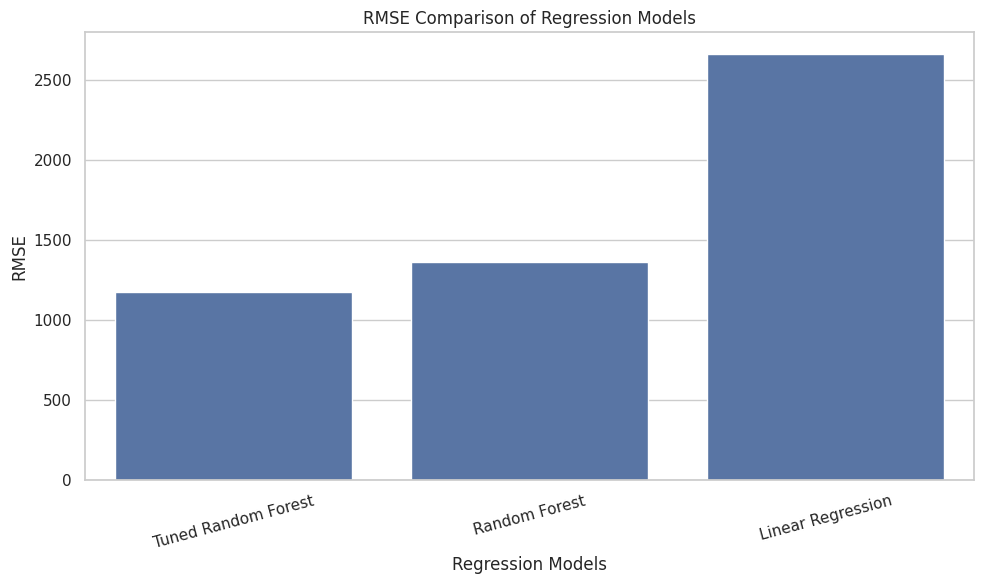

In [ ]:
# SECTION 12.1 - MODEL COMPARISON CHART

os.makedirs("outputs/charts/Task3", exist_ok=True)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=model_comparison,
    x="Model",
    y="RMSE"
)

plt.title("RMSE Comparison of Regression Models")
plt.xlabel("Regression Models")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "outputs/charts/Task3/01_model_comparison.png",
    dpi=300
)

plt.show()

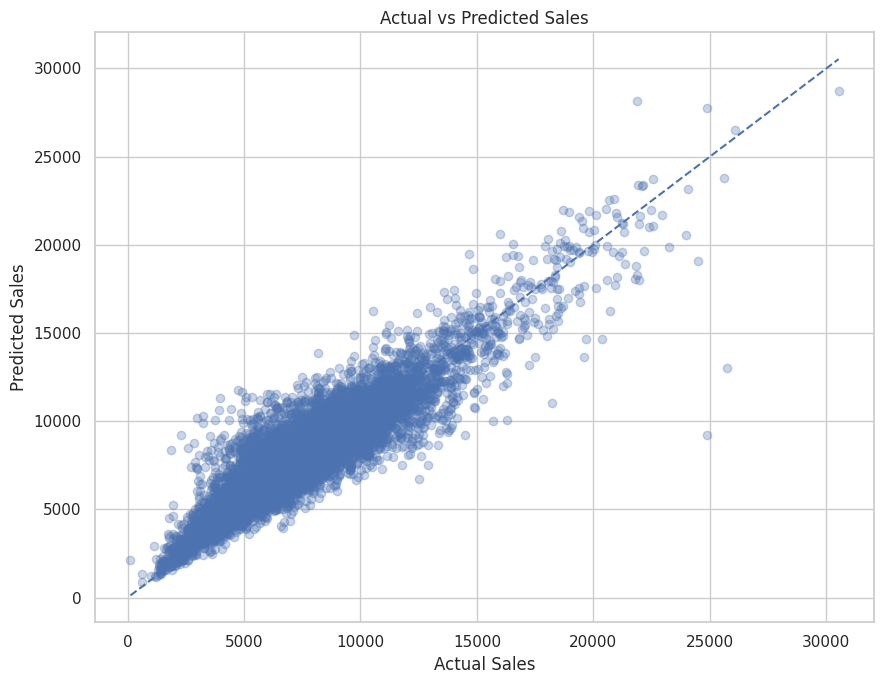

In [ ]:
# SECTION 12.2 - ACTUAL VS PREDICTED SALES

best_predictions = best_model.predict(X_valid)

plot_size = min(10000, len(y_valid))

plt.figure(figsize=(9, 7))

plt.scatter(
    y_valid.iloc[:plot_size],
    best_predictions[:plot_size],
    alpha=0.3
)

min_value = min(
    y_valid.iloc[:plot_size].min(),
    best_predictions[:plot_size].min()
)

max_value = max(
    y_valid.iloc[:plot_size].max(),
    best_predictions[:plot_size].max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.tight_layout()

plt.savefig(
    "outputs/charts/Task3/02_actual_vs_predicted.png",
    dpi=300
)

plt.show()

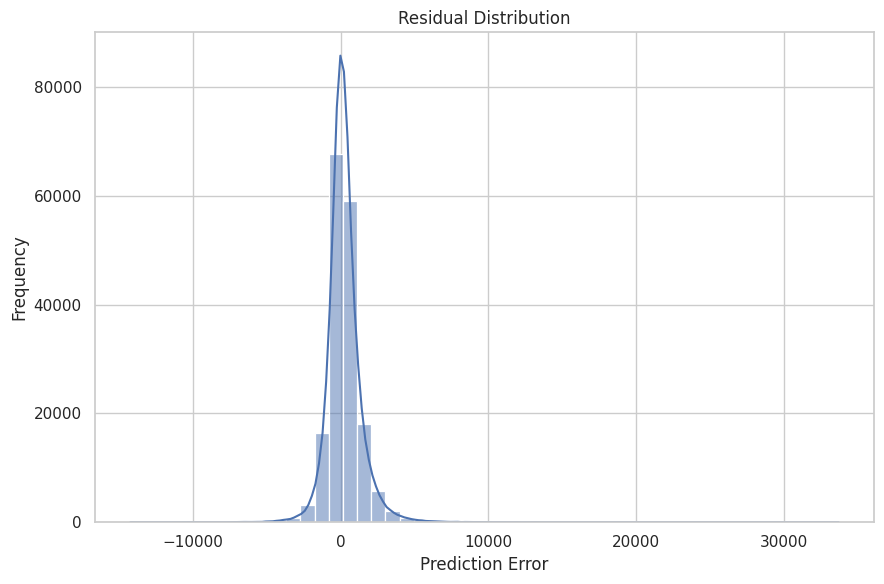

In [ ]:
# SECTION 12.3 - RESIDUAL DISTRIBUTION

residuals = y_valid - best_predictions

plt.figure(figsize=(9, 6))

sns.histplot(
    residuals,
    bins=50,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "outputs/charts/Task3/03_residual_distribution.png",
    dpi=300
)

plt.show()

In [ ]:
# SECTION 13.1 - FEATURE IMPORTANCE

fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_estimator = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_estimator, "feature_importances_"):

    importance_values = fitted_estimator.feature_importances_

    importance_type = "Random Forest Feature Importance"

else:

    importance_values = np.abs(fitted_estimator.coef_)

    importance_type = "Absolute Linear Regression Coefficients"

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
).reset_index(drop=True)

print("Top 20 Important Features:")

display(feature_importance_df.head(20))

Top 20 Important Features:


,Feature,Importance
0,numerical__competitiondistance,0.18
1,numerical__store,0.15
2,numerical__promo,0.14
3,numerical__competitionopensinceyear,0.06
4,numerical__competitionopensincemonth,0.06
5,numerical__dayofweek,0.06
6,numerical__competition_age_months,0.05
7,numerical__dayofyear,0.04
8,numerical__promo2sinceyear,0.03
9,numerical__day,0.03


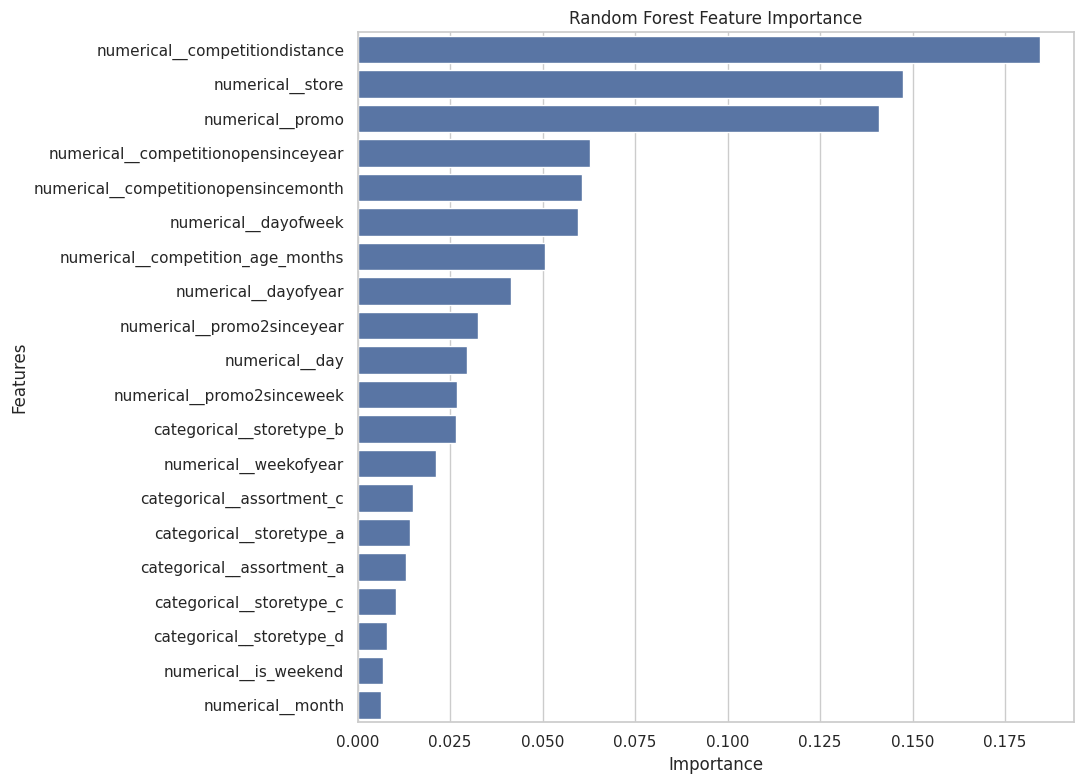

In [ ]:
# SECTION 13.2 - FEATURE IMPORTANCE VISUALIZATION

top_features = feature_importance_df.head(20)

plt.figure(figsize=(11, 8))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(importance_type)
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    "outputs/charts/Task3/04_feature_importance.png",
    dpi=300
)

plt.show()

In [ ]:
# SECTION 14.1 - PREPARE FINAL TEST PREDICTIONS

test_open_mask = model_test_df["open"] == 1

X_test_open = X_test.loc[test_open_mask].copy()

test_sales_predictions = np.zeros(len(model_test_df))

test_sales_predictions[test_open_mask.to_numpy()] = (
    best_model.predict(X_test_open)
)

print("Test Predictions Generated Successfully!")

print("\nTotal Test Records:", len(model_test_df))
print("Open Store Predictions:", test_open_mask.sum())
print("Closed Store Predictions:", (~test_open_mask).sum())

print("\nPrediction Statistics:")
print(pd.Series(test_sales_predictions).describe())

Test Predictions Generated Successfully!

Total Test Records: 41088
Open Store Predictions: 35104
Closed Store Predictions: 5984

Prediction Statistics:
count   41088.00
mean     5812.17
std      3386.98
min         0.00
25%      4227.46
50%      5923.02
75%      7682.67
max     31318.04
dtype: float64


In [ ]:
# SECTION 14.2 - CREATE FINAL SUBMISSION

test_prediction_df = pd.DataFrame({
    "Id": model_test_df["id"].astype(int).to_numpy(),
    "Sales": test_sales_predictions
})

submission = sample_submission[["Id"]].merge(
    test_prediction_df,
    on="Id",
    how="left",
    validate="one_to_one"
)

assert len(submission) == len(sample_submission)
assert submission["Sales"].notna().all()

submission["Sales"] = submission["Sales"].clip(lower=0)

print("Submission Shape:", submission.shape)

display(submission.head(10))

Submission Shape: (41088, 2)


,Id,Sales
0,1,4961.33
1,2,8034.92
2,3,8683.94
3,4,6074.12
4,5,7008.17
5,6,5884.69
6,7,7830.09
7,8,8752.34
8,9,5370.00
9,10,6077.24


In [ ]:
# SECTION 14.3 - SAVE FINAL PREDICTIONS

os.makedirs("outputs/predictions", exist_ok=True)

submission.to_csv(
    "outputs/predictions/final_sales_predictions.csv",
    index=False
)

print("Final Predictions Saved Successfully!")
print("File: outputs/predictions/final_sales_predictions.csv")

Final Predictions Saved Successfully!
File: outputs/predictions/final_sales_predictions.csv


In [ ]:
# SECTION 15.1 - SAVE BEST MODEL

os.makedirs("outputs/models", exist_ok=True)

joblib.dump(
    best_model,
    "outputs/models/best_sales_prediction_model.pkl"
)

print("Best Model Saved Successfully!")

Best Model Saved Successfully!


In [ ]:
# SECTION 15.2 - SAVE MODEL COMPARISON

model_comparison.to_csv(
    "outputs/predictions/model_comparison.csv",
    index=False
)

feature_importance_df.to_csv(
    "outputs/predictions/feature_importance.csv",
    index=False
)

print("Model Comparison Saved!")
print("Feature Importance Saved!")

Model Comparison Saved!
Feature Importance Saved!


In [ ]:
# SECTION 16 - GENERATE SALES PREDICTION REPORT

report = f"""
SALES PREDICTION - FINAL SUMMARY REPORT
========================================

1. PROJECT OVERVIEW
-------------------
Project: Rossmann Store Sales Prediction

Objective:
Predict daily sales for Rossmann stores using historical
sales information, promotions, store characteristics,
competition information and date-based features.

2. DATASET INFORMATION
----------------------
Training Records: {len(train_clean)}
Test Records: {len(test_clean)}
Store Records: {len(store_clean)}

Training Features: {len(feature_columns)}

Training Records Used:
{len(model_train_df)}

3. FEATURE ENGINEERING
----------------------
- Year
- Month
- Day
- Day of Year
- Week of Year
- Weekend Indicator
- Month Start and End Indicators
- Competition Age
- Promo2 Active Indicator

4. MODEL DEVELOPMENT
--------------------
Models Implemented:
- Linear Regression
- Random Forest Regression
- Tuned Random Forest Regression

Training Method:
Chronological 80:20 Train-Validation Split

5. MODEL PERFORMANCE
--------------------
{model_comparison.to_string(index=False)}

6. HYPERPARAMETER TUNING
------------------------
Best Parameters:
{rf_search.best_params_}

Cross-Validation RMSE:
{round(-rf_search.best_score_, 2)}

7. FINAL MODEL
--------------
Selected Model: {best_model_name}

RMSE: {round(model_comparison.loc[0, 'RMSE'], 2)}
MAE: {round(model_comparison.loc[0, 'MAE'], 2)}
R2 Score: {round(model_comparison.loc[0, 'R2 Score'], 4)}

8. TEST PREDICTIONS
-------------------
Total Predictions: {len(submission)}
Open Store Predictions: {int(test_open_mask.sum())}
Closed Store Predictions: {int((~test_open_mask).sum())}

9. CONCLUSION
-------------
The regression models were developed and evaluated using
historical Rossmann sales data.

The best-performing model was selected based on validation
RMSE. The selected model was then used to generate sales
predictions for the test dataset.

Closed stores were assigned zero sales.

========================================
END OF REPORT
========================================
"""

os.makedirs("reports", exist_ok=True)

with open(
    "reports/Sales_Prediction_Report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report)

print(report)
print("\nSales Prediction Report Saved Successfully!")


SALES PREDICTION - FINAL SUMMARY REPORT

1. PROJECT OVERVIEW
-------------------
Project: Rossmann Store Sales Prediction

Objective:
Predict daily sales for Rossmann stores using historical
sales information, promotions, store characteristics,
competition information and date-based features.

2. DATASET INFORMATION
----------------------
Training Records: 1017209
Test Records: 41088
Store Records: 1115

Training Features: 27

Training Records Used:
844392

3. FEATURE ENGINEERING
----------------------
- Year
- Month
- Day
- Day of Year
- Week of Year
- Weekend Indicator
- Month Start and End Indicators
- Competition Age
- Promo2 Active Indicator

4. MODEL DEVELOPMENT
--------------------
Models Implemented:
- Linear Regression
- Random Forest Regression
- Tuned Random Forest Regression

Training Method:
Chronological 80:20 Train-Validation Split

5. MODEL PERFORMANCE
--------------------
              Model    RMSE     MAE  R2 Score
Tuned Random Forest 1177.08  794.05      0.85
     

In [ ]:
import os

os.makedirs("outputs/models", exist_ok=True)
os.makedirs("outputs/predictions", exist_ok=True)
os.makedirs("outputs/charts/Task3", exist_ok=True)
os.makedirs("reports", exist_ok=True)
print("Task 3 output folders created successfully!")

Task 3 output folders created successfully!


In [ ]:
import joblib

# Save Linear Regression
joblib.dump(
    linear_model,
    "outputs/models/linear_regression_model.pkl"
)

# Save Random Forest
joblib.dump(
    rf_model,
    "outputs/models/random_forest_model.pkl"
)

# Save Tuned Random Forest
joblib.dump(
    rf_tuned_model,
    "outputs/models/tuned_random_forest_model.pkl"
)

# Save Best Model
joblib.dump(
    best_model,
    "outputs/models/best_sales_prediction_model.pkl"
)

print("All trained models saved successfully!")

All trained models saved successfully!


In [ ]:
# ================================================
# MODEL COMPARISON
# ================================================

model_results = []

# 1. Linear Regression
linear_predictions = linear_model.predict(X_valid)

model_results.append({
    "Model": "Linear Regression",
    "RMSE": np.sqrt(mean_squared_error(y_valid, linear_predictions)),
    "MAE": mean_absolute_error(y_valid, linear_predictions),
    "R2": r2_score(y_valid, linear_predictions)
})


# 2. Random Forest
rf_predictions = rf_model.predict(X_valid)

model_results.append({
    "Model": "Random Forest",
    "RMSE": np.sqrt(mean_squared_error(y_valid, rf_predictions)),
    "MAE": mean_absolute_error(y_valid, rf_predictions),
    "R2": r2_score(y_valid, rf_predictions)
})


# 3. Tuned Random Forest
tuned_predictions = rf_tuned_model.predict(X_valid)

model_results.append({
    "Model": "Tuned Random Forest",
    "RMSE": np.sqrt(mean_squared_error(y_valid, tuned_predictions)),
    "MAE": mean_absolute_error(y_valid, tuned_predictions),
    "R2": r2_score(y_valid, tuned_predictions)
})


# Create Comparison DataFrame
model_comparison_df = pd.DataFrame(model_results)

model_comparison_df = model_comparison_df.sort_values(
    by="RMSE",
    ascending=True
).reset_index(drop=True)


# Save CSV
model_comparison_df.to_csv(
    "outputs/predictions/model_comparison.csv",
    index=False
)

display(model_comparison_df)

print("Model comparison saved successfully!")

,Model,RMSE,MAE,R2
0,Tuned Random Forest,1177.08,794.05,0.85
1,Random Forest,1363.03,928.15,0.80
2,Linear Regression,2664.04,1946.24,0.24


Model comparison saved successfully!


In [ ]:
validation_predictions_df = pd.DataFrame({
    "Actual_Sales": y_valid.values,
    "Predicted_Sales": best_model.predict(X_valid)
})

validation_predictions_df["Prediction_Error"] = (
    validation_predictions_df["Actual_Sales"] -
    validation_predictions_df["Predicted_Sales"]
)

validation_predictions_df.to_csv(
    "outputs/predictions/validation_predictions.csv",
    index=False
)

display(validation_predictions_df.head(10))

print("Validation predictions saved successfully!")

,Actual_Sales,Predicted_Sales,Prediction_Error
0,8139,8188.67,-49.67
1,5855,6549.66,-694.66
2,5508,6936.53,-1428.53
3,5748,6305.40,-557.40
4,6300,7670.11,-1370.11
5,4273,4447.97,-174.97
6,4169,5013.89,-844.89
7,6326,6475.63,-149.63
8,5200,6491.57,-1291.57
9,5103,5891.97,-788.97


Validation predictions saved successfully!


In [ ]:
submission.to_csv(
    "outputs/predictions/final_sales_predictions.csv",
    index=False
)

display(submission.head(10))

print("Final test predictions saved successfully!")
print("Total predictions:", len(submission))

,Id,Sales
0,1,4961.33
1,2,8034.92
2,3,8683.94
3,4,6074.12
4,5,7008.17
5,6,5884.69
6,7,7830.09
7,8,8752.34
8,9,5370.00
9,10,6077.24


Final test predictions saved successfully!
Total predictions: 41088


In [ ]:
fitted_preprocessor = best_model.named_steps["preprocessor"]
fitted_model = best_model.named_steps["model"]

feature_names = fitted_preprocessor.get_feature_names_out()

if hasattr(fitted_model, "feature_importances_"):
    importance_values = fitted_model.feature_importances_

elif hasattr(fitted_model, "coef_"):
    importance_values = np.abs(fitted_model.coef_)

else:
    raise ValueError("Selected model does not support feature importance.")

feature_importance_df = pd.DataFrame({
    "Feature": feature_names,
    "Importance": importance_values
})

feature_importance_df = feature_importance_df.sort_values(
    by="Importance",
    ascending=False
)

feature_importance_df.to_csv(
    "outputs/predictions/feature_importance.csv",
    index=False
)

display(feature_importance_df.head(15))

print("Feature importance saved successfully!")

,Feature,Importance
16,numerical__competitiondistance,0.18
15,numerical__store,0.15
22,numerical__promo,0.14
19,numerical__competitionopensinceyear,0.06
18,numerical__competitionopensincemonth,0.06
29,numerical__dayofweek,0.06
21,numerical__competition_age_months,0.05
33,numerical__dayofyear,0.04
25,numerical__promo2sinceyear,0.03
32,numerical__day,0.03


Feature importance saved successfully!


In [ ]:
import os

os.makedirs("outputs/visualizations/Task3", exist_ok=True)

print("Task 3 visualization folder is ready.")

Task 3 visualization folder is ready.


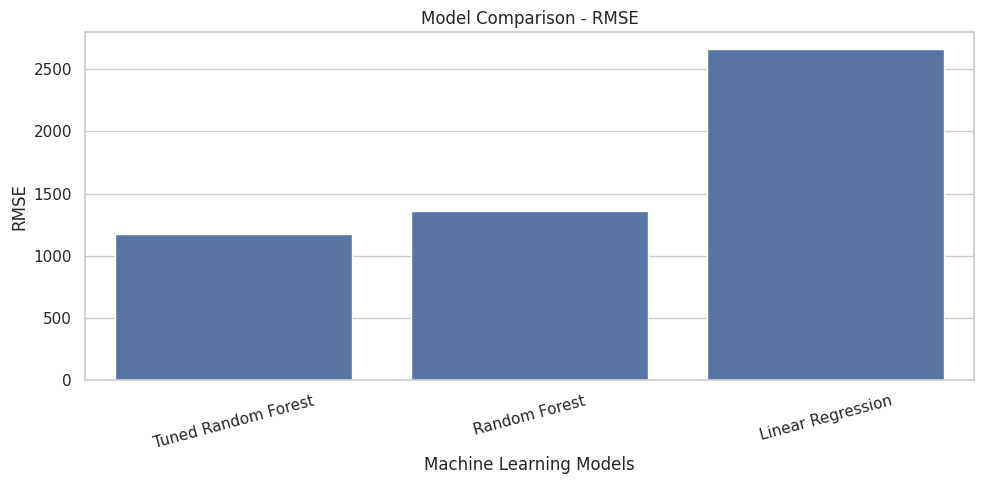

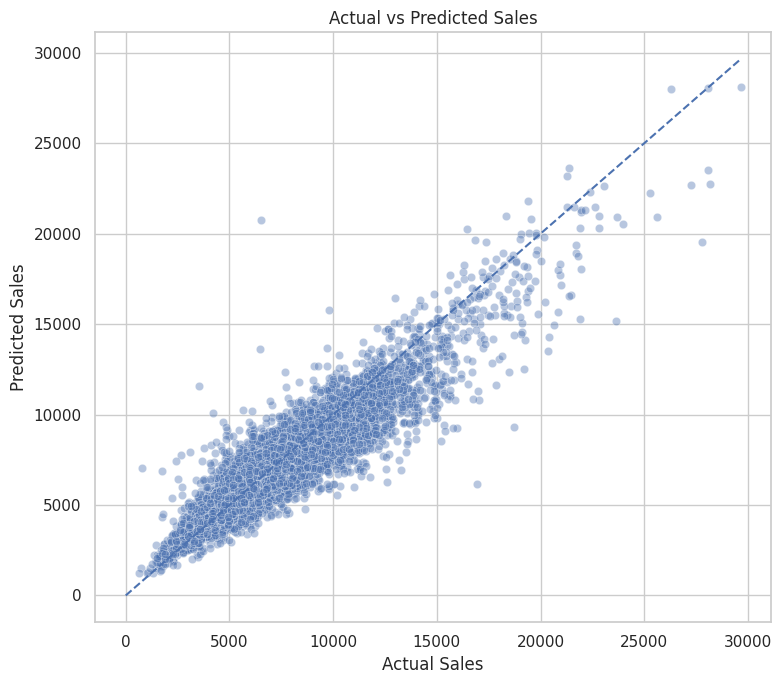

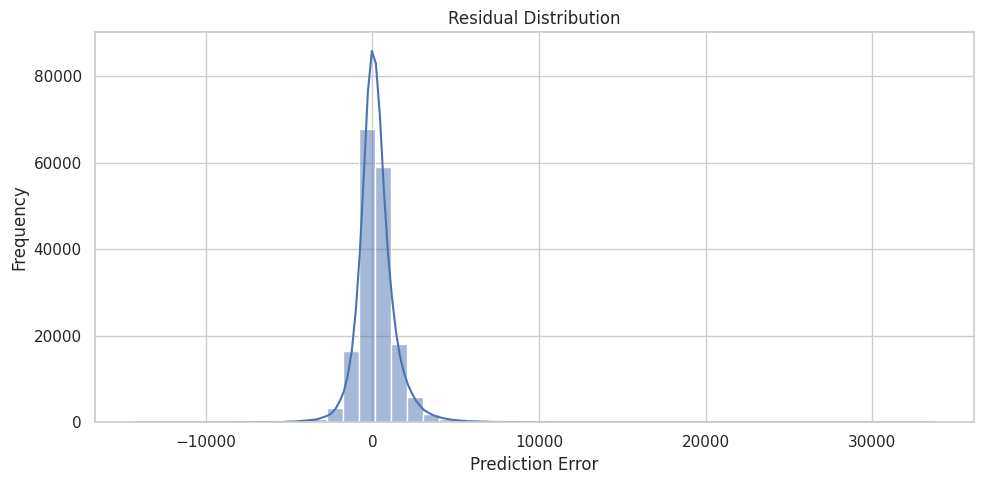

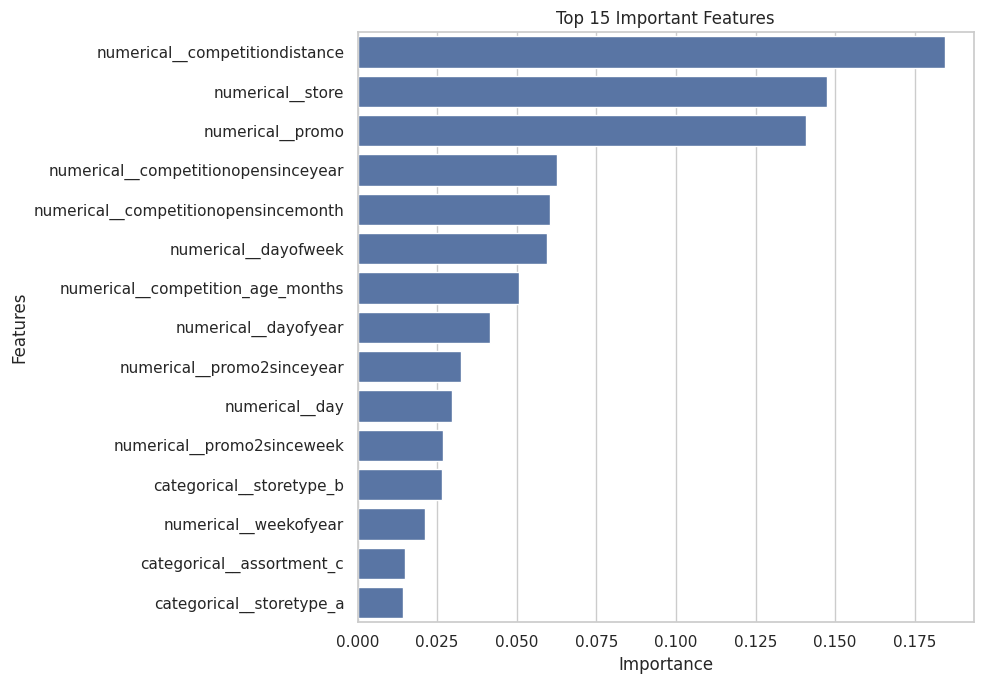

ALL TASK 3 VISUALIZATIONS SAVED SUCCESSFULLY
Total Visualizations: 4


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

# Use a sample for faster plotting
validation_sample = validation_predictions_df.sample(
    n=min(10000, len(validation_predictions_df)),
    random_state=42
)

# 1. MODEL COMPARISON

plt.figure(figsize=(10, 5))

sns.barplot(
    data=model_comparison_df,
    x="Model",
    y="RMSE"
)

plt.title("Model Comparison - RMSE")
plt.xlabel("Machine Learning Models")
plt.ylabel("RMSE")
plt.xticks(rotation=15)
plt.tight_layout()

plt.savefig(
    "outputs/visualizations/Task3/01_model_comparison.png",
    dpi=300
)

plt.show()


# 2. ACTUAL VS PREDICTED SALES

plt.figure(figsize=(8, 7))

sns.scatterplot(
    data=validation_sample,
    x="Actual_Sales",
    y="Predicted_Sales",
    alpha=0.4
)

plt.plot(
    [0, validation_sample["Actual_Sales"].max()],
    [0, validation_sample["Actual_Sales"].max()],
    linestyle="--"
)

plt.title("Actual vs Predicted Sales")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.tight_layout()

plt.savefig(
    "outputs/visualizations/Task3/02_actual_vs_predicted.png",
    dpi=300
)

plt.show()


# 3. RESIDUAL DISTRIBUTION

plt.figure(figsize=(10, 5))

sns.histplot(
    data=validation_predictions_df,
    x="Prediction_Error",
    bins=50,
    kde=True
)

plt.title("Residual Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")
plt.tight_layout()

plt.savefig(
    "outputs/visualizations/Task3/03_residual_distribution.png",
    dpi=300
)

plt.show()


# 4. FEATURE IMPORTANCE

plt.figure(figsize=(10, 7))

sns.barplot(
    data=feature_importance_df.head(15),
    x="Importance",
    y="Feature"
)

plt.title("Top 15 Important Features")
plt.xlabel("Importance")
plt.ylabel("Features")
plt.tight_layout()

plt.savefig(
    "outputs/visualizations/Task3/04_feature_importance.png",
    dpi=300
)

plt.show()


print("=" * 55)
print("ALL TASK 3 VISUALIZATIONS SAVED SUCCESSFULLY")
print("=" * 55)

print(
    "Total Visualizations:",
    len(os.listdir("outputs/visualizations/Task3"))
)

In [ ]:
best_model_name = str(model_comparison_df.iloc[0]["Model"])

best_metrics = model_comparison_df.iloc[0]

report_text = f"""
========================================================
             ROSSMANN STORE SALES
             SALES PREDICTION REPORT
========================================================

1. PROJECT OVERVIEW
--------------------------------------------------------
Project: Rossmann Store Sales Prediction
Task: Task 3 - Sales Prediction

Objective:
To predict daily store sales using Machine Learning
models based on historical sales and store information.


2. DATASET INFORMATION
--------------------------------------------------------
Training Records: {len(train_clean):,}
Testing Records: {len(test_clean):,}
Store Records: {len(store_clean):,}

Training Features: {len(feature_columns)}

Training Date Range:
{model_train_df['date'].min()} to {model_train_df['date'].max()}


3. DATA PREPROCESSING
--------------------------------------------------------
- Cleaned datasets were used.
- Training and testing datasets were merged with store data.
- Missing values were checked.
- Categorical variables were encoded.
- Numerical features were retained.


4. FEATURE ENGINEERING
--------------------------------------------------------
- Year
- Month
- Day
- Day of Year
- Week of Year
- Weekend Indicator
- Month Start and Month End
- Competition Age
- Promotion Activity


5. MODEL DEVELOPMENT
--------------------------------------------------------
The following Machine Learning models were developed:

1. Linear Regression
2. Random Forest Regressor
3. Tuned Random Forest Regressor


6. MODEL EVALUATION
--------------------------------------------------------
Evaluation Metrics:
- Root Mean Squared Error (RMSE)
- Mean Absolute Error (MAE)
- R2 Score

MODEL COMPARISON:

{model_comparison_df.to_string(index=False)}


7. BEST MODEL
--------------------------------------------------------
Selected Model: {best_model_name}

RMSE: {best_metrics['RMSE']:.2f}
MAE: {best_metrics['MAE']:.2f}
R2 Score: {best_metrics['R2']:.4f}


8. HYPERPARAMETER TUNING
--------------------------------------------------------
RandomizedSearchCV was used for Random Forest
hyperparameter optimization.

Best Parameters:
{rf_search.best_params_}

Best Cross-Validation RMSE:
{-rf_search.best_score_:.2f}


9. FEATURE IMPORTANCE
--------------------------------------------------------
Top 15 Features:

{feature_importance_df.head(15).to_string(index=False)}


10. VALIDATION PREDICTIONS
--------------------------------------------------------
Total Validation Predictions:
{len(validation_predictions_df):,}

Actual and predicted sales were compared
to evaluate model performance.


11. FINAL TEST PREDICTIONS
--------------------------------------------------------
Total Test Predictions:
{len(submission):,}

Final sales predictions were generated
for the test dataset.


12. OUTPUT FILES
--------------------------------------------------------

MODELS:
- linear_regression_model.pkl
- random_forest_model.pkl
- tuned_random_forest_model.pkl
- best_sales_prediction_model.pkl

PREDICTIONS:
- model_comparison.csv
- validation_predictions.csv
- final_sales_predictions.csv
- feature_importance.csv

VISUALIZATIONS:
- 01_model_comparison.png
- 02_actual_vs_predicted.png
- 03_residual_distribution.png
- 04_feature_importance.png

REPORTS:
- Sales_Prediction_Report.txt
- Sales_Prediction_Report.pdf


13. CONCLUSION
--------------------------------------------------------
Three Machine Learning models were developed and
evaluated for Rossmann store sales prediction.

The best-performing model was selected based on
validation performance.

Feature importance analysis was performed to
identify important sales prediction factors.

Final predictions were generated for the test dataset.


========================================================
                  END OF REPORT
========================================================
"""

with open(
    "reports/Sales_Prediction_Report.txt",
    "w",
    encoding="utf-8"
) as file:
    file.write(report_text)

print("Sales Prediction TXT Report generated successfully!")

Sales Prediction TXT Report generated successfully!


In [ ]:
!pip -q install reportlab

In [ ]:
from reportlab.lib.pagesizes import A4
from reportlab.platypus import (
    SimpleDocTemplate,
    Paragraph,
    Spacer,
    Preformatted
)
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import inch
from xml.sax.saxutils import escape

pdf_path = "reports/Sales_Prediction_Report.pdf"

document = SimpleDocTemplate(
    pdf_path,
    pagesize=A4,
    rightMargin=40,
    leftMargin=40,
    topMargin=40,
    bottomMargin=40
)

styles = getSampleStyleSheet()

story = [
    Paragraph(
        "ROSSMANN STORE SALES - SALES PREDICTION REPORT",
        styles["Title"]
    ),
    Spacer(1, 0.3 * inch),
    Preformatted(
        escape(report_text),
        styles["Code"]
    )
]

document.build(story)

print("Sales Prediction PDF Report generated successfully!")

Sales Prediction PDF Report generated successfully!


In [ ]:
print("=" * 65)
print("TASK 3 - FINAL OUTPUT VERIFICATION")
print("=" * 65)

for root, directories, filenames in os.walk("outputs"):
    for filename in sorted(filenames):
        filepath = os.path.join(root, filename)
        size_kb = os.path.getsize(filepath) / 1024

        print(f"{filepath}  |  {size_kb:.2f} KB")

print("\nREPORT FILES")
print("-" * 65)

for root, directories, filenames in os.walk("reports"):
    for filename in sorted(filenames):
        filepath = os.path.join(root, filename)
        size_kb = os.path.getsize(filepath) / 1024

        print(f"{filepath}  |  {size_kb:.2f} KB")

print("\nTASK 3 OUTPUT VERIFICATION COMPLETED!")

TASK 3 - FINAL OUTPUT VERIFICATION
outputs/visualizations/Task3/01_model_comparison.png  |  134.21 KB
outputs/visualizations/Task3/02_actual_vs_predicted.png  |  753.32 KB
outputs/visualizations/Task3/03_residual_distribution.png  |  106.22 KB
outputs/visualizations/Task3/04_feature_importance.png  |  239.41 KB
outputs/predictions/feature_importance.csv  |  1.83 KB
outputs/predictions/final_sales_predictions.csv  |  873.68 KB
outputs/predictions/model_comparison.csv  |  0.23 KB
outputs/predictions/validation_predictions.csv  |  7185.96 KB
outputs/charts/Task3/01_model_comparison.png  |  145.82 KB
outputs/charts/Task3/02_actual_vs_predicted.png  |  653.65 KB
outputs/charts/Task3/03_residual_distribution.png  |  109.96 KB
outputs/charts/Task3/04_feature_importance.png  |  305.06 KB
outputs/models/best_sales_prediction_model.pkl  |  303079.40 KB
outputs/models/linear_regression_model.pkl  |  5.29 KB
outputs/models/random_forest_model.pkl  |  124377.56 KB
outputs/models/tuned_random_forest

In [ ]:
import zipfile
from google.colab import files

zip_filename = "Sales_Prediction_Deliverables.zip"

with zipfile.ZipFile(
    zip_filename,
    "w",
    zipfile.ZIP_DEFLATED
) as zipf:

    # Add trained models
    for root, dirs, filenames in os.walk("outputs/models"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

    # Add predictions
    for root, dirs, filenames in os.walk("outputs/predictions"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

    # Add visualizations
    for root, dirs, filenames in os.walk("outputs/visualizations/Task3"):
        for filename in filenames:
            filepath = os.path.join(root, filename)
            zipf.write(filepath, filepath)

    # Add reports
    for filename in os.listdir("reports"):
        if filename.startswith("Sales_Prediction_Report"):
            filepath = os.path.join("reports", filename)
            zipf.write(filepath, filepath)

print("ZIP file created successfully!")

with zipfile.ZipFile(zip_filename, "r") as zipf:
    print("Total files:", len(zipf.namelist()))
    for filename in zipf.namelist():
        print(filename)

files.download(zip_filename)

ZIP file created successfully!
Total files: 14
outputs/models/tuned_random_forest_model.pkl
outputs/models/best_sales_prediction_model.pkl
outputs/models/random_forest_model.pkl
outputs/models/linear_regression_model.pkl
outputs/predictions/model_comparison.csv
outputs/predictions/final_sales_predictions.csv
outputs/predictions/feature_importance.csv
outputs/predictions/validation_predictions.csv
outputs/visualizations/Task3/03_residual_distribution.png
outputs/visualizations/Task3/02_actual_vs_predicted.png
outputs/visualizations/Task3/01_model_comparison.png
outputs/visualizations/Task3/04_feature_importance.png
reports/Sales_Prediction_Report.txt
reports/Sales_Prediction_Report.pdf


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>